# Random Forest for music genre classification

ISC 4241 group project · Five broad genres · 14 song descriptors

A Random Forest trains many decision trees on bootstrap samples drawn with replacement. At each split, a tree considers a random subset of features and chooses a split that reduces class mixing, measured here by Gini impurity. Each tree estimates class probabilities from the songs in its leaf. The forest averages those probabilities across trees and predicts the genre with the highest average. Sampling rows and features helps the trees make different errors.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import cross_val_predict, cross_validate

cwd = Path.cwd()
repo_root = next((path for path in (cwd, *cwd.parents) if (path / "common.py").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Start Jupyter in the group repository with common.py at its root.")
sys.path.insert(0, str(repo_root))

from common import FEATURES, GENRES, load, random_forest

d = load()
model = random_forest()
# Materialize once so every experiment uses the same shared folds.
shared_folds = list(d.cv.split(d.X_train, d.y_train) if hasattr(d.cv, "split") else d.cv)
print(len(d.X_train), "train songs,", len(d.X_test), "test songs")

36037 train songs, 9009 test songs


## Data and frozen settings

The training set contains 36,037 training songs. Hip-hop/R&B accounts for 1,525 (4.23%), the smallest class. The frozen configuration uses 300 bootstrap trees, a minimum of five samples per leaf, and equal class weights. Each experiment clones this configuration and changes one setting at a time.

In [2]:
# Examine our Random Forest model and dataset

print("FEATURES:")
print(FEATURES)

print("\nGENRES:")
print(GENRES)

print("\nSONGS PER GENRE:")
print(d.y_train.value_counts())

print("\nRANDOM FOREST SETTINGS:")
print(model.get_params())

FEATURES:
['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

GENRES:
['electronic', 'hiphop/rnb', 'latin', 'pop', 'rock']

SONGS PER GENRE:
broad_genre
electronic    10920
rock           9529
pop            8165
latin          5898
hiphop/rnb     1525
Name: count, dtype: int64

RANDOM FOREST SETTINGS:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 300, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


## Tree depth and overfitting · Shared cross-validation

Each point averages accuracy across the same shared folds. Training accuracy is measured on the training portion of each fold. The second curve uses that fold's held-out songs. From depth 5 to no cap, the gap grows from 1.2 to 22.6 percentage points. Validation accuracy improves at first and then nearly flattens, while training accuracy keeps rising. Depth 20 reaches 64.6% validation accuracy, within about 0.1 percentage point of the uncapped model. That is a possible simpler setting. The displayed means alone cannot establish a dependable advantage for either depth.

Depth 5: Train=0.591, CV=0.579
Depth 10: Train=0.691, CV=0.623
Depth 15: Train=0.814, CV=0.643
Depth 20: Train=0.866, CV=0.646
Depth None: Train=0.873, CV=0.647


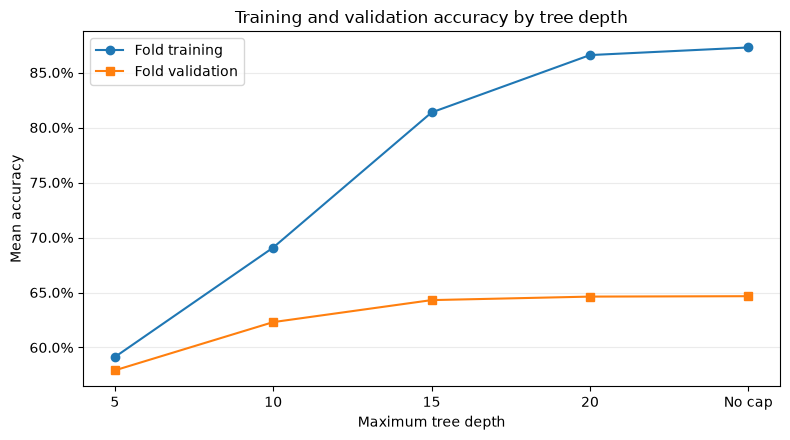

In [3]:
depths = [5, 10, 15, 20, None]
train_scores = []
cv_scores = []

for depth in depths:
    rf = clone(model)
    rf.set_params(max_depth=depth, n_jobs=1)

    scores = cross_validate(
        rf,
        d.X_train,
        d.y_train,
        cv=shared_folds,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=-1
    )

    train_acc = scores["train_score"].mean()
    cv_acc = scores["test_score"].mean()

    train_scores.append(train_acc)
    cv_scores.append(cv_acc)

    print(f"Depth {depth}: Train={train_acc:.3f}, CV={cv_acc:.3f}")


fig, ax = plt.subplots(figsize=(8, 4.5))
positions = range(len(depths))
ax.plot(positions, train_scores, marker="o", label="Fold training")
ax.plot(positions, cv_scores, marker="s", label="Fold validation")
ax.set(
    xticks=list(positions),
    xticklabels=["No cap" if depth is None else str(depth) for depth in depths],
    xlabel="Maximum tree depth",
    ylabel="Mean accuracy",
    title="Training and validation accuracy by tree depth",
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Class weighting · Shared cross-validation

`balanced` uses inverse-frequency weights from each fold's training portion. `balanced_subsample` recomputes weights from each tree's bootstrap sample. Macro F1 gives each genre equal weight. `balanced_subsample` had the highest mean macro F1 (0.579 versus 0.553 unweighted), while mean accuracy decreased from 64.7% to 63.8%. The separate sweeps compare depth and weight one at a time. Their results do not establish the best joint setting. The same folds are used to compare candidates, so these scores describe model selection.

In [4]:
weights = [None, "balanced", "balanced_subsample"]

for weight in weights:
    rf = clone(model)
    rf.set_params(class_weight=weight, n_jobs=1)

    scores = cross_validate(
        rf,
        d.X_train,
        d.y_train,
        cv=shared_folds,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        },
        n_jobs=-1
    )

    print(f"Class weight: {weight}")
    print(f"Mean validation accuracy: {scores['test_accuracy'].mean():.3f}")
    print(f"Mean validation macro F1: {scores['test_macro_f1'].mean():.3f}")
    print("---------------------------")

Class weight: None
Mean validation accuracy: 0.647
Mean validation macro F1: 0.553
---------------------------
Class weight: balanced
Mean validation accuracy: 0.629
Mean validation macro F1: 0.573
---------------------------
Class weight: balanced_subsample
Mean validation accuracy: 0.638
Mean validation macro F1: 0.579
---------------------------


### Why hip-hop/R&B is difficult

The unweighted forest recognized only about 10% of hip-hop/R&B songs in out-of-fold predictions. With `balanced_subsample`, recall rose to about 33% and F1 rose from 0.17 to 0.31. Precision fell from 0.57 to 0.29, so the model recovered more tracks at the cost of more false alarms. The small training share makes class imbalance a plausible contributor. Weighting does not by itself show why individual songs are confused.

For each weight setting, I pooled one held-out prediction per training song. The confusion counts show where true hip-hop/R&B songs went and which other genres produced false hip-hop/R&B predictions. Pooled metrics and mean fold scores use different averaging procedures.

| Weight | Hip-hop/R&B precision | Recall | F1 |
|---|---:|---:|---:|
| None | 0.57 | 0.10 | 0.17 |
| balanced_subsample | 0.29 | 0.33 | 0.31 |

In [5]:
# Inspect out-of-fold predictions for each class-weight setting.
target = "hiphop/rnb"
target_index = GENRES.index(target)
for weight in weights:
    rf = clone(model).set_params(class_weight=weight, n_jobs=1)
    cv_predictions = cross_val_predict(
        rf, d.X_train, d.y_train, cv=shared_folds, n_jobs=-1
    )
    print(f"\nCLASS WEIGHT: {weight}")
    print(classification_report(d.y_train, cv_predictions, labels=GENRES, zero_division=0))
    counts = confusion_matrix(d.y_train, cv_predictions, labels=GENRES)
    display(pd.DataFrame(
        {"True hip-hop/R&B predicted as": counts[target_index, :],
         "Predicted hip-hop/R&B actually was": counts[:, target_index]},
        index=GENRES,
    ).rename_axis("Genre"))


CLASS WEIGHT: None
              precision    recall  f1-score   support

  electronic       0.72      0.75      0.73     10920
  hiphop/rnb       0.57      0.10      0.17      1525
       latin       0.63      0.64      0.63      5898
         pop       0.52      0.56      0.54      8165
        rock       0.69      0.69      0.69      9529

    accuracy                           0.65     36037
   macro avg       0.63      0.55      0.55     36037
weighted avg       0.65      0.65      0.64     36037



,True hip-hop/R&B predicted as,Predicted hip-hop/R&B actually was
Genre,,
electronic,333,33
hiphop/rnb,149,149
latin,313,25
pop,590,17
rock,140,38



CLASS WEIGHT: balanced
              precision    recall  f1-score   support

  electronic       0.78      0.68      0.73     10920
  hiphop/rnb       0.23      0.41      0.30      1525
       latin       0.58      0.69      0.63      5898
         pop       0.53      0.53      0.53      8165
        rock       0.71      0.65      0.68      9529

    accuracy                           0.63     36037
   macro avg       0.57      0.59      0.57     36037
weighted avg       0.65      0.63      0.64     36037



,True hip-hop/R&B predicted as,Predicted hip-hop/R&B actually was
Genre,,
electronic,149,612
hiphop/rnb,620,620
latin,290,396
pop,400,625
rock,66,397



CLASS WEIGHT: balanced_subsample
              precision    recall  f1-score   support

  electronic       0.77      0.70      0.73     10920
  hiphop/rnb       0.29      0.33      0.31      1525
       latin       0.59      0.69      0.63      5898
         pop       0.52      0.56      0.54      8165
        rock       0.71      0.66      0.68      9529

    accuracy                           0.64     36037
   macro avg       0.58      0.59      0.58     36037
weighted avg       0.65      0.64      0.64     36037



,True hip-hop/R&B predicted as,Predicted hip-hop/R&B actually was
Genre,,
electronic,185,355
hiphop/rnb,496,496
latin,310,244
pop,463,344
rock,71,258


## Which features did the forest use?

A clone with the frozen settings is fitted to all training songs for this analysis. Acousticness (16.8%) estimates how acoustic a track sounds. Danceability (14.4%) summarizes how suited the track is to dancing based on factors such as rhythm and tempo. Instrumentalness (14.1%) estimates how likely a track is to lack vocals. Together they account for about 45.3% of the normalized impurity reduction. They capture differences in production, rhythm, and vocal presence that the trees can use to separate genres.

These are global, training-fitted Gini importances. They can favor features with more possible split points, and correlated features can share importance. The ranking does not show which direction a feature pushes a prediction or explain hip-hop/R&B errors on its own.

FEATURE IMPORTANCE:
acousticness        0.168088
danceability        0.144190
instrumentalness    0.141101
valence             0.088118
duration_ms         0.084514
energy              0.076050
speechiness         0.067257
liveness            0.065313
tempo               0.064557
loudness            0.055921
key                 0.023251
explicit            0.010989
mode                0.007946
time_signature      0.002706
dtype: float64


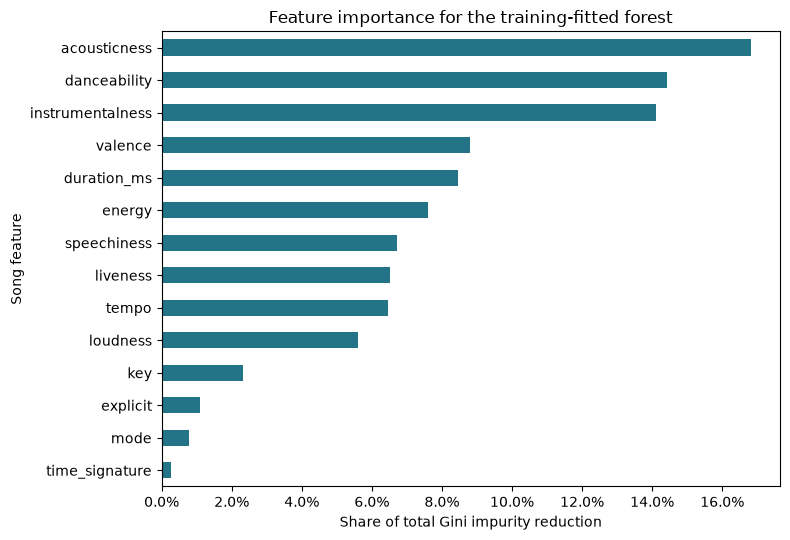

In [6]:
# Train a copy of the original model
rf_features = clone(model)
rf_features.fit(d.X_train, d.y_train)

# Calculate feature importance
importance = pd.Series(
    rf_features.feature_importances_,
    index=d.X_train.columns
).sort_values(ascending=False)

print("FEATURE IMPORTANCE:")
print(importance)


fig, ax = plt.subplots(figsize=(8, 5.5))
importance.sort_values().plot(kind="barh", ax=ax, color="#227486")
ax.set(
    xlabel="Share of total Gini impurity reduction",
    ylabel="Song feature",
    title="Feature importance for the training-fitted forest",
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
plt.show()

## Official test performance · Frozen saved predictions

I scored the group’s frozen predictions in `predictions/random_forest.csv` using the actual and predicted genres paired in each row. The notebook checks the CSV for valid genre labels and unique track IDs, then compares its row count and class counts with the shared test split. The depth and class-weight experiments used the shared training folds.

In [7]:
preds = pd.read_csv(repo_root / "predictions" / "random_forest.csv")
required_columns = ["track_id", "broad_genre", "predicted"]
if not set(required_columns).issubset(preds.columns):
    raise ValueError("The frozen prediction CSV is missing required columns.")
if len(preds) != len(d.y_test) or preds[required_columns].isna().any().any():
    raise ValueError("The frozen prediction CSV has missing values or the wrong row count.")
if not preds["track_id"].is_unique:
    raise ValueError("The frozen prediction CSV contains repeated track IDs.")
if not preds[["broad_genre", "predicted"]].isin(GENRES).all().all():
    raise ValueError("The frozen prediction CSV contains unexpected genre labels.")
if preds["broad_genre"].value_counts().to_dict() != d.y_test.value_counts().to_dict():
    raise ValueError("The frozen CSV label counts differ from the shared test split.")
print(f"{len(preds):,} rows in the frozen predictions CSV.")

9,009 rows in the frozen predictions CSV.


OFFICIAL RANDOM FOREST TEST RESULTS
-----------------------------------
Accuracy: 0.640
Macro F1: 0.556

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  electronic       0.71      0.78      0.74      2730
  hiphop/rnb       0.63      0.13      0.21       381
       latin       0.64      0.64      0.64      1474
         pop       0.50      0.52      0.51      2041
        rock       0.68      0.66      0.67      2383

    accuracy                           0.64      9009
   macro avg       0.63      0.55      0.56      9009
weighted avg       0.64      0.64      0.63      9009



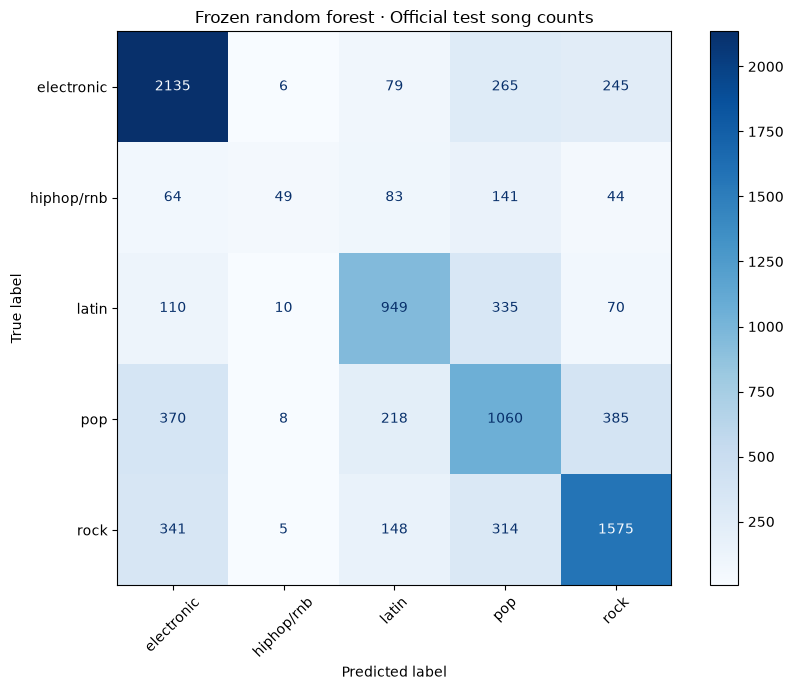

In [8]:
y_true = preds["broad_genre"]
y_pred = preds["predicted"]

# Calculate performance metrics
print("OFFICIAL RANDOM FOREST TEST RESULTS")
print("-----------------------------------")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.3f}")
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro', labels=GENRES):.3f}")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_true,
    y_pred,
    labels=GENRES,
    zero_division=0
))

# Create confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=GENRES,
    display_labels=GENRES,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set(title="Frozen random forest · Official test song counts")
plt.tight_layout()
plt.show()

### Conclusion

The frozen model correctly classified 5,768 of 9,009 test songs (**64.0% accuracy**, **0.556 macro F1**). It identified 49 of 381 hip-hop/R&B tracks (**12.9% recall**). Pop was the most frequent wrong label for those tracks (141), followed by Latin (83). The weighting experiments used training folds only. `balanced_subsample` improved minority-class recall and macro F1 there, with lower hip-hop/R&B precision and lower overall accuracy. The official test numbers describe the original frozen forest.